# Analisis Sentimen Komentar YouTube
## Perbandingan SVM (TF-IDF) vs IndoBERT

**Topik:** Perubahan kebijakan pajak kendaraan listrik di Indonesia  
**Kelas:** Negatif (0) Â· Netral (1) Â· Positif (2)  
**Dataset:** 4.645 komentar YouTube (hasil pelabelan manual)

| Tahap | Isi |
|-------|-----|
| 1 | Import Library |
| 2 | Load & Cleaning Data |
| 3 | Preprocessing Dual Pipeline |
| 4 | Analisis Distribusi Label |
| 5 | Split Dataset + Class Imbalance |
| 6 | Training SVM |
| 7 | Training IndoBERT |
| 8 | Evaluasi & Visualisasi |
| 9 | Perbandingan Akhir (McNemar) |


---
## 1. Install & Import Library


In [ ]:
!pip install -q PySastrawi transformers torch datasets accelerate
!pip install -q scikit-learn pandas numpy matplotlib seaborn wordcloud requests
!pip install -q emoji imbalanced-learn

---
## 2. Load & Cleaning Data

Data komentar dimuat dari CSV, dibersihkan (null, noise, duplikat), dan diberi label sentimen.


In [ ]:
import pandas as pd
import numpy as np
import re, warnings, time
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter
import random, torch

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.dpi'] = 120

# -- Set seed --
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)

# -- Cek GPU --
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {device.upper()}')
if device == 'cuda':
  print(f'GPU: {torch.cuda.get_device_name(0)}')

# â”€â”€ Load file CSV berlabel â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# Ganti nama file sesuai file Anda yang sudah dilabeling manual
INPUT_FILE = 'data/processed/hasil_komentar_bersih_berlabel.csv'

df_raw = pd.read_csv(INPUT_FILE)
df_raw.columns = df_raw.columns.str.strip().str.lower()

assert 'comment' in df_raw.columns, "Kolom 'comment' tidak ditemukan!"
assert 'label'  in df_raw.columns, "Kolom 'label' tidak ditemukan!"

nama_label = {0: 'Negatif', 1: 'Netral', 2: 'Positif'}
label_map  = {'negatif': 0, 'netral': 1, 'positif': 2}

df_raw['comment'] = df_raw['comment'].astype(str).str.strip()
df_raw['label']  = df_raw['label'].astype(str).str.strip().str.lower().map(label_map)


# Rename ke kolom standar
df = df_raw[['comment', 'label']].copy()
df.rename(columns={'comment': 'text'}, inplace=True)
df['text'] = df['text'].astype(str).str.strip()

# Hapus label NULL sebelum preprocessing (semestinya di Tahap 1)
df.dropna(subset=['label'], inplace=True)

# Hapus duplikat exact sebelum split (anti data leakage)
n_sebelum = len(df)
df.drop_duplicates(subset=['text'], keep='first', inplace=True)
df.reset_index(drop=True, inplace=True)
n_sesudah = len(df)
print(f'Hapus duplikat: {n_sebelum:,} â†’ {n_sesudah:,} baris ({n_sebelum - n_sesudah} duplikat dihapus)')

vc = df['label'].value_counts().sort_index()
print(f'\nFile  : {INPUT_FILE}')
print(f'Jumlah baris : {len(df):,}')
print(f'\nDistribusi label:')
for k, v in vc.items():
  pct = v / len(df) * 100
  print(f'  {nama_label[k]:8s}: {v:,} ({pct:.1f}%)')

df[['text', 'label']].head(5)


Device: CUDA
GPU: Tesla T4
Hapus duplikat: 4,645 â†’ 4,645 baris (0 duplikat dihapus)

File  : hasil_komentar_bersih_berlabel.csv
Jumlah baris : 4,645

Distribusi label:
  Negatif : 3,153 (67.9%)
  Netral  : 867 (18.7%)
  Positif : 625 (13.5%)


,text,label
0,Ah purbaya ngomong doang sma aja ternyata kya ...,0
1,"Pemerintah panic cari masukkan , satu2 ny yg m...",0
2,Dulunya gembar gembor bigini begono gak taunya...,0
3,Yg jd viral pajak apaan yg dijawab lain ! ðŸ˜‚ðŸ˜‚ðŸ˜‚,0
4,"Awalnya dikasih diskon biar pada pindah,pas se...",0


---
## 3. Preprocessing Dual Pipeline

- **SVM:** case folding â†’ cleaning & emoji â†’ normalisasi slang â†’ negasi â†’ stopword â†’ stemming
- **IndoBERT:** cleaning & emoji saja (minimal, agar konteks terjaga)


### 2.1 Case Folding (hanya SVM)


In [ ]:
def case_folding(text):
  return text.lower() if isinstance(text, str) else ''

df['step1_casefold'] = df['text'].apply(case_folding)
print(' Case Folding selesai')
df[['text', 'step1_casefold']].head(3)


 Case Folding selesai


,text,step1_casefold
0,Ah purbaya ngomong doang sma aja ternyata kya ...,ah purbaya ngomong doang sma aja ternyata kya ...
1,"Pemerintah panic cari masukkan , satu2 ny yg m...","pemerintah panic cari masukkan , satu2 ny yg m..."
2,Dulunya gembar gembor bigini begono gak taunya...,dulunya gembar gembor bigini begono gak taunya...


### 2.2 Cleaning & Konversi Emoji


In [ ]:
import emoji as emoji_lib

def konversi_emoji(text):
  """Konversi emoji ke teks Indonesia. Contoh:  â†’ 'wajah menangis tertawa'."""
  if not isinstance(text, str): return ''
  try:
    text = emoji_lib.demojize(text, language='id', delimiters=(' ', ' '))
  except TypeError:
    text = emoji_lib.demojize(text, delimiters=(' ', ' '))
  return re.sub(r'\s+', ' ', text).strip()

def cleaning_svm(text):
  if not isinstance(text, str): return ''
  import unicodedata
  text = unicodedata.normalize('NFKC', text)
  text = konversi_emoji(text)
  text = re.sub(r'http\S+|www\.\S+|@\w+|#\w+', '', text)
  text = re.sub(r'\d+', '', text)
  text = re.sub(r'(.)\1{2,}', r'\1\1', text)
  text = re.sub(r'[^\w\s]', ' ', text)
  return re.sub(r'\s+', ' ', text).strip()

def cleaning_indobert(text):
  if not isinstance(text, str): return ''
  text = konversi_emoji(text)
  text = re.sub(r'http\S+|www\.\S+|@\w+|#\w+', '', text)
  return re.sub(r'\s+', ' ', text).strip()

# SVM pakai teks lowercase, IndoBERT pakai teks ORIGINAL (tidak lowercase)
df['step2a_clean_svm']  = df['step1_casefold'].apply(cleaning_svm)
df['step2b_clean_bert'] = df['text'].apply(cleaning_indobert)

print(' Cleaning selesai')
df[['text', 'step2a_clean_svm', 'step2b_clean_bert']].head(5)

 Cleaning selesai


,text,step2a_clean_svm,step2b_clean_bert
0,Ah purbaya ngomong doang sma aja ternyata kya ...,ah purbaya ngomong doang sma aja ternyata kya ...,Ah purbaya ngomong doang sma aja ternyata kya ...
1,"Pemerintah panic cari masukkan , satu2 ny yg m...",pemerintah panic cari masukkan satu ny yg mere...,"Pemerintah panic cari masukkan , satu2 ny yg m..."
2,Dulunya gembar gembor bigini begono gak taunya...,dulunya gembar gembor bigini begono gak taunya...,Dulunya gembar gembor bigini begono gak taunya...
3,Yg jd viral pajak apaan yg dijawab lain ! ðŸ˜‚ðŸ˜‚ðŸ˜‚,yg jd viral pajak apaan yg dijawab lain wajah_...,Yg jd viral pajak apaan yg dijawab lain ! waja...
4,"Awalnya dikasih diskon biar pada pindah,pas se...",awalnya dikasih diskon biar pada pindah pas se...,"Awalnya dikasih diskon biar pada pindah,pas se..."


### 2.3 Normalisasi Slang (hanya SVM)


In [ ]:
!pip install indonlp==0.2.0
from indoNLP.preprocessing import replace_slang

def normalisasi(text):
    if isinstance(text, str):
        try:
            return replace_slang(text)
        except KeyError:

            return text
    return text

df['step3_normalisasi'] = df['step2a_clean_svm'].apply(normalisasi)
df[['step2a_clean_svm', 'step3_normalisasi']].head()

,step2a_clean_svm,step3_normalisasi
0,ah purbaya ngomong doang sma aja ternyata kya ...,ah purbaya mengomong doang sama saja ternyata ...
1,pemerintah panic cari masukkan satu ny yg mere...,pemerintah panic cari masukkan satu nya yang m...
2,dulunya gembar gembor bigini begono gak taunya...,dulunya gembar gembor bigini begono enggak tau...
3,yg jd viral pajak apaan yg dijawab lain wajah_...,yang jadi viral pajak apaan yang dijawab lain ...
4,awalnya dikasih diskon biar pada pindah pas se...,awalnya dikasih diskon biar pada pindah pas se...


### 2.4 Penanganan Negasi (hanya SVM)


In [ ]:
KATA_NEGASI = {'tidak','bukan','jangan','belum','tanpa','tak','tiada'}

def negation_handling(text):
  if not isinstance(text, str): return ''
  tokens, hasil, i = text.split(), [], 0
  while i < len(tokens):
    if tokens[i] in KATA_NEGASI and i + 1 < len(tokens):
      hasil.append(tokens[i] + '_' + tokens[i+1])
      i += 2
    else:
      hasil.append(tokens[i])
      i += 1
  return ' '.join(hasil)

df['step4_negasi'] = df['step3_normalisasi'].apply(negation_handling)

ada_negasi = df['step4_negasi'].str.contains('tidak_|bukan_|jangan_|belum_|tak_', na=False)
print(f' Negation Handling selesai')
print(f'  Kalimat dengan negasi: {ada_negasi.sum():,}')
df[ada_negasi]['step4_negasi'].head(3).to_frame()

 Negation Handling selesai
  Kalimat dengan negasi: 828


,step4_negasi
11,kenapa segala kebijakan baru di indonesia sela...
12,dulu pemerintah bilang bebas pajak untuk pemak...
18,saatnya kendaraan listrik ikut kontribusi pemb...


### 2.5 Stopword Removal (hanya SVM)


In [ ]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')

kata_penting = {'tidak','bukan','jangan','belum','tanpa','tak','tiada'}

stopword = set(stopwords.words('indonesian')) - kata_penting

def remove_stopwords(text):
    if not isinstance(text, str):
        return text

    words = text.split()
    filtered_words = [word for word in words if word.lower() not in stopword]

    return ' '.join(filtered_words)

df['Stopword_removal'] = df['step4_negasi'].apply(remove_stopwords)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### 2.6 Stemming (hanya SVM)


In [ ]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

factory = StemmerFactory()
stemmer = factory.create_stemmer()

def stemming(text):
    if not isinstance(text, str):
        return ''

    return ' '.join(
        word if '_' in word else stemmer.stem(word)
        for word in text.split()
    )

df['step6_stem'] = df['Stopword_removal'].apply(stemming)
print('Stemming selesai')
df[['Stopword_removal', 'step6_stem']].head()

Stemming selesai


,Stopword_removal,step6_stem
0,ah purbaya mengomong doang kaya,ah purbaya omong doang kaya
1,pemerintah panic cari masukkan nya menyusahkan...,perintah panic cari masuk nya susah rkyat waja...
2,dulunya gembar gembor bigini begono taunya tip...,dulunya gembar gembor bigini begono tau tipu t...
3,viral pajak wajah_gembira_berurai_air_mata waj...,viral pajak wajah_gembira_berurai_air_mata waj...
4,dikasih diskon biar pindah pas tagihannya paja...,kasih diskon biar pindah pas tagih pajak banda...


### 2.7 Kolom Final Preprocessing


In [ ]:
# Gunakan step6_stem (sudah di-stem) sebagai teks final SVM
df['teks_svm']  = df['step6_stem']
df['teks_indobert'] = df['step2b_clean_bert']

kosong_svm  = (df['teks_svm'].isna()  | (df['teks_svm'].str.strip()  == '')).sum()
kosong_bert = (df['teks_indobert'].isna() | (df['teks_indobert'].str.strip() == '')).sum()

print('Pipeline SVM  : casefold â†’ cleaning â†’ slang â†’ negasi â†’ stopword â†’ stemming â†’ TF-IDF')
print('Pipeline IndoBERT : cleaning minimal (teks original) â†’ tokenizer IndoBERT')
print(f'Teks SVM kosong  : {kosong_svm}')
print(f'Teks BERT kosong  : {kosong_bert}')
print(f'Total data siap  : {len(df):,}')
df[['text', 'teks_svm', 'teks_indobert', 'label']].head(5)


Pipeline SVM  : casefold â†’ cleaning â†’ slang â†’ negasi â†’ stopword â†’ stemming â†’ TF-IDF
Pipeline IndoBERT : cleaning minimal (teks original) â†’ tokenizer IndoBERT
Teks SVM kosong  : 18
Teks BERT kosong  : 0
Total data siap  : 4,645


,text,teks_svm,teks_indobert,label
0,Ah purbaya ngomong doang sma aja ternyata kya ...,ah purbaya omong doang kaya,Ah purbaya ngomong doang sma aja ternyata kya ...,0
1,"Pemerintah panic cari masukkan , satu2 ny yg m...",perintah panic cari masuk nya susah rkyat waja...,"Pemerintah panic cari masukkan , satu2 ny yg m...",0
2,Dulunya gembar gembor bigini begono gak taunya...,dulunya gembar gembor bigini begono tau tipu t...,Dulunya gembar gembor bigini begono gak taunya...,0
3,Yg jd viral pajak apaan yg dijawab lain ! ðŸ˜‚ðŸ˜‚ðŸ˜‚,viral pajak wajah_gembira_berurai_air_mata waj...,Yg jd viral pajak apaan yg dijawab lain ! waja...,0
4,"Awalnya dikasih diskon biar pada pindah,pas se...",kasih diskon biar pindah pas tagih pajak banda...,"Awalnya dikasih diskon biar pada pindah,pas se...",0


### 3.1 Simpan Dataset Preprocessed


In [ ]:
df[['text', 'teks_svm', 'teks_indobert', 'label']].to_csv('outputs/reports/data_preprocessing.csv', index=False)
print(f' Tersimpan: data_preprocessing.csv ({len(df):,} baris)')


 Tersimpan: data_preprocessing.csv (4,645 baris)


---
## 4. Analisis Distribusi Label

Memeriksa proporsi kelas Negatif / Netral / Positif dan menyimpan dataset preprocessed.


In [ ]:
vc = df['label'].value_counts().sort_index()

print('Distribusi label:')
for k, v in vc.items():
  pct = v / len(df) * 100
  print(f'  {nama_label[k]:8s}: {v:,} ({pct:.1f}%)')

# dropna sudah dilakukan di Tahap 1 â€” hanya assert saja
assert df['label'].isna().sum() == 0, 'Ada label null â€” periksa file input!'
print(f'\nTotal data siap diproses: {len(df):,} baris')
df[['text', 'teks_svm', 'teks_indobert', 'label']].head(5)

Distribusi label:
  Negatif : 3,153 (67.9%)
  Netral  : 867 (18.7%)
  Positif : 625 (13.5%)

Total data siap diproses: 4,645 baris


,text,teks_svm,teks_indobert,label
0,Ah purbaya ngomong doang sma aja ternyata kya ...,ah purbaya omong doang kaya,Ah purbaya ngomong doang sma aja ternyata kya ...,0
1,"Pemerintah panic cari masukkan , satu2 ny yg m...",perintah panic cari masuk nya susah rkyat waja...,"Pemerintah panic cari masukkan , satu2 ny yg m...",0
2,Dulunya gembar gembor bigini begono gak taunya...,dulunya gembar gembor bigini begono tau tipu t...,Dulunya gembar gembor bigini begono gak taunya...,0
3,Yg jd viral pajak apaan yg dijawab lain ! ðŸ˜‚ðŸ˜‚ðŸ˜‚,viral pajak wajah_gembira_berurai_air_mata waj...,Yg jd viral pajak apaan yg dijawab lain ! waja...,0
4,"Awalnya dikasih diskon biar pada pindah,pas se...",kasih diskon biar pindah pas tagih pajak banda...,"Awalnya dikasih diskon biar pada pindah,pas se...",0


### 3.2 Visualisasi Distribusi Label


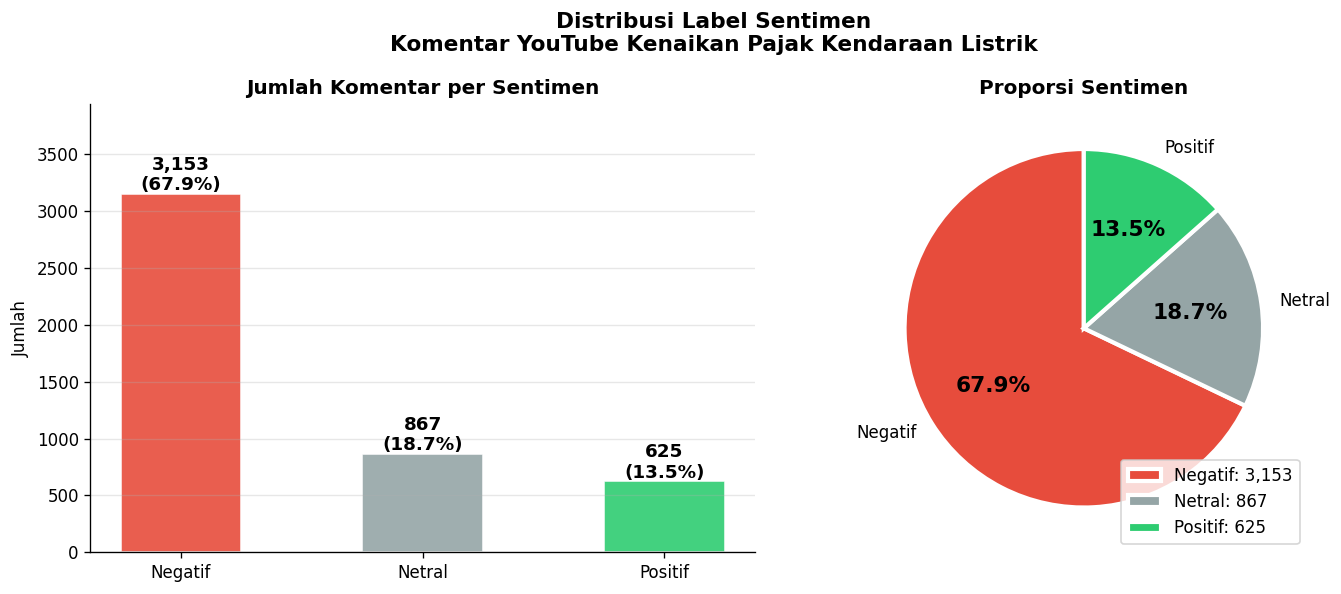

 Distribusi label ditampilkan.


In [ ]:
dist = df['label'].value_counts().sort_index()
xlabels = [nama_label[i] for i in dist.index]
total = len(df)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Distribusi Label Sentimen\nKomentar YouTube Kenaikan Pajak Kendaraan Listrik',
  fontsize=13, fontweight='bold')

colors = ['#e74c3c', '#95a5a6', '#2ecc71']

bars = axes[0].bar(xlabels, dist.values, color=colors, edgecolor='white', width=0.5, alpha=0.9)
axes[0].set_title('Jumlah Komentar per Sentimen', fontweight='bold')
axes[0].set_ylabel('Jumlah')
axes[0].set_ylim(0, max(dist.values) * 1.25)
axes[0].grid(axis='y', alpha=0.3)
axes[0].spines[['top', 'right']].set_visible(False)
for bar, v in zip(bars, dist.values):
  axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+30,
  f'{v:,}\n({v/total*100:.1f}%)', ha='center', fontsize=11, fontweight='bold')

wedges, texts, autotexts = axes[1].pie(
  dist.values, labels=xlabels, colors=colors,
  autopct='%1.1f%%', startangle=90,
  wedgeprops={'edgecolor':'white','linewidth':2.5})
for at in autotexts:
  at.set_fontweight('bold'); at.set_fontsize(13)
axes[1].set_title('Proporsi Sentimen', fontweight='bold')
axes[1].legend([f'{nama_label[i]}: {v:,}' for i,v in zip(dist.index, dist.values)], loc='lower right')

plt.tight_layout()
plt.show()
print(' Distribusi label ditampilkan.')


---
## 5. Split Dataset + Penanganan Class Imbalance

**Urutan wajib:**
1. Stratified split (80:20, 75:25, 70:30)
2. TF-IDF fit hanya pada train (SVM)
3. RandomOverSampler **hanya pada training**
4. Class weight / WeightedTrainer (diterapkan saat training)

Data test & validation tetap distribusi asli.


### 4.1 Setup Konfigurasi Split


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from imblearn.over_sampling import RandomOverSampler
import scipy.sparse as sp

# Saring data valid (baris dengan teks_svm kosong dibuang sebelum modeling)
df_model = df[df['teks_svm'].notna() & (df['teks_svm'].str.strip() != '')].copy()
df_model.reset_index(drop=True, inplace=True)

X_raw_svm  = df_model['teks_svm'].values
X_raw_bert = df_model['teks_indobert'].values
y  = df_model['label'].values



### 4.2 Split + TF-IDF + Oversampling â€” SVM

Urutan di dalam cell:
1. `train_test_split` (stratified)
2. `TfidfVectorizer.fit` hanya pada train â†’ transform test
3. `RandomOverSampler` **hanya pada train** (setelah TF-IDF)


In [ ]:
from collections import Counter
splits_config = {'80/20': 0.20, '75/25': 0.25, '70/30': 0.30}
splits_order  = ['80/20', '75/25', '70/30']
split_data = {}
for split_label, test_size in splits_config.items():
  Xtr_r, Xte_r, ytr, yte = train_test_split(
  X_raw_svm, y, test_size=test_size, random_state=42, stratify=y)

  # 2. TF-IDF di-fit dari data training ASLI sebelum oversampling (anti leakage)

  tfidf = TfidfVectorizer(
  ngram_range=(1, 3),
  max_features=15_000,
  sublinear_tf=True,
  min_df=2,
  max_df=0.85,
  analyzer='word',
  token_pattern=r'\b[a-z_][a-z_]{1,}\b',
  )
  Xtr_tfidf = tfidf.fit_transform(Xtr_r)
  Xte_tfidf = tfidf.transform(Xte_r)

  # 3. RandomOverSampler HANYA pada training set
  ros = RandomOverSampler(random_state=42)
  Xtr_res, ytr_res = ros.fit_resample(Xtr_tfidf, ytr)

  unique_before, counts_before = np.unique(ytr, return_counts=True)
  unique_after,  counts_after  = np.unique(ytr_res, return_counts=True)

  split_data[split_label] = {
  'X_train': Xtr_res,  'X_test': Xte_tfidf,
  'y_train': ytr_res,  'y_test': yte,
  'X_train_raw': Xtr_r, 'X_test_raw': Xte_r,
  # PERBAIKAN: simpan data ASLI sebelum oversample untuk GridSearch & class weight
  'X_train_orig': Xtr_tfidf, 'y_train_orig': ytr,
  'tfidf': tfidf,
  }
  print(f'[SVM] Split {split_label}:')
  print(f'  Test set (tidak diubah) : {len(yte):,} | Fitur TF-IDF: {Xtr_tfidf.shape[1]:,}')
  print(f'  Train sebelum oversample: {dict(zip(unique_before, counts_before))}')
  print(f'  Train sesudah oversample: {dict(zip(unique_after, counts_after))}  â†’ total={len(ytr_res):,}')
  # Verifikasi distribusi kelas setelah split
  dist_train = Counter(ytr)
  dist_test  = Counter(yte)
  print(f'  Distribusi kelas train (asli): { {nama_label[k]:v for k,v in sorted(dist_train.items())} }')
  print(f'  Distribusi kelas test  : { {nama_label[k]:v for k,v in sorted(dist_test.items())} }')

print('\n Split data SVM (3 skenario) siap.')


[SVM] Split 80/20:
  Test set (tidak diubah) : 926 | Fitur TF-IDF: 6,703
  Train sebelum oversample: {np.int64(0): np.int64(2522), np.int64(1): np.int64(681), np.int64(2): np.int64(498)}
  Train sesudah oversample: {np.int64(0): np.int64(2522), np.int64(1): np.int64(2522), np.int64(2): np.int64(2522)}  â†’ total=7,566
  Distribusi kelas train (asli): {'Negatif': 2522, 'Netral': 681, 'Positif': 498}
  Distribusi kelas test  : {'Negatif': 631, 'Netral': 171, 'Positif': 124}
[SVM] Split 75/25:
  Test set (tidak diubah) : 1,157 | Fitur TF-IDF: 6,330
  Train sebelum oversample: {np.int64(0): np.int64(2365), np.int64(1): np.int64(639), np.int64(2): np.int64(466)}
  Train sesudah oversample: {np.int64(0): np.int64(2365), np.int64(1): np.int64(2365), np.int64(2): np.int64(2365)}  â†’ total=7,095
  Distribusi kelas train (asli): {'Negatif': 2365, 'Netral': 639, 'Positif': 466}
  Distribusi kelas test  : {'Negatif': 788, 'Netral': 213, 'Positif': 156}
[SVM] Split 70/30:
  Test set (tidak diubah)

### 4.3 Split + Oversampling â€” IndoBERT

Urutan di dalam cell:
1. Split train+val vs test (stratified)
2. Split train vs val dari sisa training
3. `RandomOverSampler` **hanya pada train** (teks mentah)
4. Simpan juga `y_train_original` (sebelum OS) â†’ dipakai hitung class weight


In [ ]:
bert_split_config = {
  '80/20': {'test': 0.20, 'val_from_train': 0.125},
  '75/25': {'test': 0.25, 'val_from_train': 0.1333},
  '70/30': {'test': 0.30, 'val_from_train': 0.1429},
}
bert_split_data = {}
print()
for split_label, cfg in bert_split_config.items():
  Xtr_tmp, Xte, ytr_tmp, yte = train_test_split(
  X_raw_bert, y, test_size=cfg['test'], random_state=42, stratify=y)
  Xtr, Xval, ytr, yval = train_test_split(
  Xtr_tmp, ytr_tmp, test_size=cfg['val_from_train'], random_state=42, stratify=ytr_tmp)

  # Oversampling teks untuk IndoBERT
  ros_bert = RandomOverSampler(random_state=42)
  idx_arr  = np.arange(len(Xtr)).reshape(-1, 1)
  idx_res, ytr_res = ros_bert.fit_resample(idx_arr, ytr)
  Xtr_os  = Xtr[idx_res.flatten()]

  bert_split_data[split_label] = {
  'X_train': Xtr_os,  'X_val': Xval,  'X_test': Xte,
  'y_train': ytr_res, 'y_val': yval,  'y_test': yte,
  # PERBAIKAN: simpan data asli untuk class weight
  'y_train_original': ytr,
  }
  n = len(y)
  print(f'[IndoBERT] Split {split_label}: '
  f'Train={len(Xtr_os):,} (OS dari {len(Xtr):,}) | '
  f'Val={len(Xval):,} ({len(Xval)/n*100:.0f}%) | '
  f'Test={len(Xte):,} ({len(Xte)/n*100:.0f}%)')
  # Verifikasi distribusi kelas IndoBERT
  dist_ytr = Counter(ytr); dist_yte = Counter(yte); dist_yval = Counter(yval)
  print(f'  Train: { {nama_label[k]:v for k,v in sorted(dist_ytr.items())} }')
  print(f'  Val  : { {nama_label[k]:v for k,v in sorted(dist_yval.items())} }')
  print(f'  Test : { {nama_label[k]:v for k,v in sorted(dist_yte.items())} }')

print('\n Split data IndoBERT (3 skenario) siap â€” oversampling hanya pada training.')



[IndoBERT] Split 80/20: Train=6,618 (OS dari 3,238) | Val=463 (10%) | Test=926 (20%)
  Train: {'Negatif': 2206, 'Netral': 596, 'Positif': 436}
  Val  : {'Negatif': 316, 'Netral': 85, 'Positif': 62}
  Test : {'Negatif': 631, 'Netral': 171, 'Positif': 124}
[IndoBERT] Split 75/25: Train=6,147 (OS dari 3,007) | Val=463 (10%) | Test=1,157 (25%)
  Train: {'Negatif': 2049, 'Netral': 554, 'Positif': 404}
  Val  : {'Negatif': 316, 'Netral': 85, 'Positif': 62}
  Test : {'Negatif': 788, 'Netral': 213, 'Positif': 156}
[IndoBERT] Split 70/30: Train=5,673 (OS dari 2,775) | Val=463 (10%) | Test=1,389 (30%)
  Train: {'Negatif': 1891, 'Netral': 511, 'Positif': 373}
  Val  : {'Negatif': 316, 'Netral': 85, 'Positif': 62}
  Test : {'Negatif': 946, 'Netral': 256, 'Positif': 187}

 Split data IndoBERT (3 skenario) siap â€” oversampling hanya pada training.


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

# Saring data valid (baris dengan teks_svm kosong dibuang sebelum modeling)
df_model = df[df['teks_svm'].notna() & (df['teks_svm'].str.strip() != '')].copy()
df_model.reset_index(drop=True, inplace=True)

y_all = df_model['label'].values
unique, counts = np.unique(y_all, return_counts=True)
rasio = counts.max() / counts.min()

print(f'Data setelah filter (teks_svm valid): {len(df_model):,} baris')
print(f'Rasio imbalance (kelas mayoritas / minoritas): {rasio:.2f}x')

# Class weight dipakai nanti oleh WeightedTrainer IndoBERT (Tahap 6B)
cw = compute_class_weight('balanced', classes=unique, y=y_all)
class_weight_dict = dict(zip(unique, cw))
print(f'Class weights  : { {k: round(v,4) for k,v in class_weight_dict.items()} }')


Data setelah filter (teks_svm valid): 4,627 baris
Rasio imbalance (kelas mayoritas / minoritas): 5.07x
Class weights  : {np.int64(0): np.float64(0.4892), np.int64(1): np.float64(1.8103), np.int64(2): np.float64(2.4796)}


---
## 6. Training Model SVM

1. GridSearchCV mencari C optimal (data asli, sebelum OS)
2. LinearSVC + `class_weight='balanced'` + CalibratedClassifierCV
3. Evaluasi pada test set


### 6A.1 GridSearch â€” Cari C Optimal per Split


In [ ]:
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
  f1_score, roc_auc_score, classification_report, confusion_matrix)

hasil_semua = []
cm_store  = {}

# GridSearch dijalankan TERPISAH untuk setiap split (C optimal bisa berbeda)
# karena ukuran training set berbeda di tiap split
print('â³ Mencari C terbaik via GridSearchCV per split (data asli, cv=5)...')
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
best_C_per_split = {}

for split_label in splits_order:
  search = GridSearchCV(
  CalibratedClassifierCV(LinearSVC(class_weight='balanced', max_iter=3000, random_state=42), cv=3),
  {'estimator__C': [0.001, 0.01, 0.05, 0.1, 0.3, 0.5, 1.0]},
  cv=skf, scoring='f1_macro', n_jobs=-1)
  search.fit(split_data[split_label]['X_train_orig'], split_data[split_label]['y_train_orig'])
  best_C_per_split[split_label] = search.best_params_['estimator__C']
  print(f'  Split {split_label}: C terbaik={best_C_per_split[split_label]} | CV F1-macro={search.best_score_:.4f}')
best_C = best_C_per_split['80/20']
print(f'\n GridSearch per split selesai: {best_C_per_split}')


â³ Mencari C terbaik via GridSearchCV per split (data asli, cv=5)...
  Split 80/20: C terbaik=0.3 | CV F1-macro=0.6048
  Split 75/25: C terbaik=0.3 | CV F1-macro=0.5945
  Split 70/30: C terbaik=0.5 | CV F1-macro=0.5717

 GridSearch per split selesai: {'80/20': 0.3, '75/25': 0.3, '70/30': 0.5}


### 6A.2 Fungsi Evaluasi Model


In [ ]:
def evaluasi_model(nama, model, X_tr, y_tr, X_tr_orig, y_tr_orig, X_te, y_te, split):
  """
  Latih model lalu evaluasi.
  - X_tr / y_tr  : data training (sudah oversampled) â†’ untuk melatih model
  - X_tr_orig / y_tr_orig : data asli (sebelum oversample) â†’ untuk ukur acc_train yang jujur
  - X_te / y_te  : data test â†’ tidak pernah dilihat model
  """
  t0 = time.time()
  model.fit(X_tr, y_tr)
  waktu_train = time.time() - t0

  #  PERBAIKAN: acc_train diukur dari data ASLI, bukan data duplikat
  acc_train = accuracy_score(y_tr_orig, model.predict(X_tr_orig))

  t0 = time.time()
  y_pred = model.predict(X_te)
  waktu_pred = time.time() - t0
  y_prob = model.predict_proba(X_te)

  acc  = accuracy_score(y_te, y_pred)
  prec = precision_score(y_te, y_pred, average='macro', zero_division=0)
  rec  = recall_score(y_te, y_pred, average='macro', zero_division=0)
  f1  = f1_score(y_te, y_pred, average='macro', zero_division=0)
  auc  = roc_auc_score(y_te, y_prob, multi_class='ovr', average='macro')
  cm  = confusion_matrix(y_te, y_pred)
  cr  = classification_report(y_te, y_pred,
  target_names=['Negatif','Netral','Positif'],
  zero_division=0)
  gap  = acc_train - acc
  flag = 'ï¸  Overfitting' if gap > 0.15 else ' OK'

  hasil_semua.append({
  'Model': nama, 'Split': split,
  'Akurasi Train': round(acc_train, 4),
  'Akurasi': round(acc, 4), 'Precision': round(prec, 4),
  'Recall': round(rec, 4), 'F1-Score': round(f1, 4),
  'ROC-AUC': round(auc, 4),
  'Waktu Train (s)': round(waktu_train, 3),
  'Waktu Pred (s)': round(waktu_pred, 4),
  })
  cm_store[f'{nama}_{split}'] = (cm, cr, y_pred, y_prob)
  print(f'  Train={acc_train:.4f} | Test={acc:.4f} | Gap={gap:.4f} â†’ {flag}')
  print(f'  F1={f1:.4f} | AUC={auc:.4f}')
  return model


### 6A.3 Training SVM â€” 3 Skenario Split


In [ ]:
print('\nâ³ Melatih SVM pada 3 split...')
for split_label in splits_order:
  print(f'\nâ”€â”€ Split {split_label} â”€â”€')
  # Gunakan C optimal per split masing-masing
  c_split = best_C_per_split.get(split_label, best_C)
  print(f'  Menggunakan C={c_split} (optimal untuk split {split_label})')
  model_svm = CalibratedClassifierCV(
  LinearSVC(C=c_split, class_weight='balanced', max_iter=3000, random_state=42), cv=3)
  evaluasi_model(
  'SVM', model_svm,
  split_data[split_label]['X_train'],  split_data[split_label]['y_train'],  # oversampled
  split_data[split_label]['X_train_orig'],  split_data[split_label]['y_train_orig'],  # asli
  split_data[split_label]['X_test'],  split_data[split_label]['y_test'],
  split_label)

print('\n SVM selesai.')



â³ Melatih SVM pada 3 split...

â”€â”€ Split 80/20 â”€â”€
  Menggunakan C=0.3 (optimal untuk split 80/20)
  Train=0.9468 | Test=0.7387 | Gap=0.2081 â†’ ï¸  Overfitting
  F1=0.6350 | AUC=0.8513

â”€â”€ Split 75/25 â”€â”€
  Menggunakan C=0.3 (optimal untuk split 75/25)
  Train=0.9470 | Test=0.7364 | Gap=0.2106 â†’ ï¸  Overfitting
  F1=0.6420 | AUC=0.8528

â”€â”€ Split 70/30 â”€â”€
  Menggunakan C=0.5 (optimal untuk split 70/30)
  Train=0.9676 | Test=0.7408 | Gap=0.2268 â†’ ï¸  Overfitting
  F1=0.6389 | AUC=0.8522

 SVM selesai.


---
## 7. Training Model IndoBERT

1. Analisis token length â†’ MAX_LEN=200
2. WeightedTrainer (loss berbobot + label smoothing 0.1)
3. Fine-tuning `indobenchmark/indobert-base-p1`
4. Early stopping patience=4


In [ ]:
import torch.nn as nn
from torch.utils.data import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
  TrainingArguments, Trainer, EarlyStoppingCallback)
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# -- Dataset PyTorch --
class KomentarDataset(Dataset):
  def __init__(self, texts, labels, tokenizer, max_len=128):
    self.enc = tokenizer(list(texts), truncation=True, padding='max_length',
    max_length=max_len, return_tensors='pt')
    self.labels = torch.tensor(list(labels), dtype=torch.long)

  def __len__(self):
    return len(self.labels)

  def __getitem__(self, idx):
    item = {k: v[idx] for k, v in self.enc.items()}
    item['labels'] = self.labels[idx]
    return item

# -- Fungsi metrik untuk Trainer --
def compute_metrics(eval_pred):
  logits, labels = eval_pred
  preds = np.argmax(logits, axis=-1)
  return {
  'accuracy' : accuracy_score(labels, preds),
  'f1'  : f1_score(labels, preds, average='macro', zero_division=0),
  'precision': precision_score(labels, preds, average='macro', zero_division=0),
  'recall'  : recall_score(labels, preds, average='macro', zero_division=0),
  }

print(' Kelas dataset dan fungsi metrik siap.')

 Kelas dataset dan fungsi metrik siap.


In [ ]:
MODEL_NAME = 'indobenchmark/indobert-base-p1'
print(f' Loading tokenizer & model: {MODEL_NAME}')

tokenizer_bert = AutoTokenizer.from_pretrained(MODEL_NAME)
model_bert  = AutoModelForSequenceClassification.from_pretrained(
  MODEL_NAME, num_labels=3, ignore_mismatched_sizes=True)
model_bert  = model_bert.to(device)

n_params = sum(p.numel() for p in model_bert.parameters())
print(f' IndoBERT dimuat | Total parameter: {n_params:,}')


 Loading tokenizer & model: indobenchmark/indobert-base-p1


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


 IndoBERT dimuat | Total parameter: 124,443,651


### 6B.0 Analisis Distribusi Token Length


 Mengukur distribusi panjang token komentar...

Distribusi panjang token (termasuk [CLS] & [SEP]):
  Median (50%)  : 23 token
  Pct 75%  : 39 token
  Pct 90%  : 60 token
  Pct 95%  : 77 token  â† referensi MAX_LEN
  Pct 99%  : 122 token
  Maximum  : 509 token


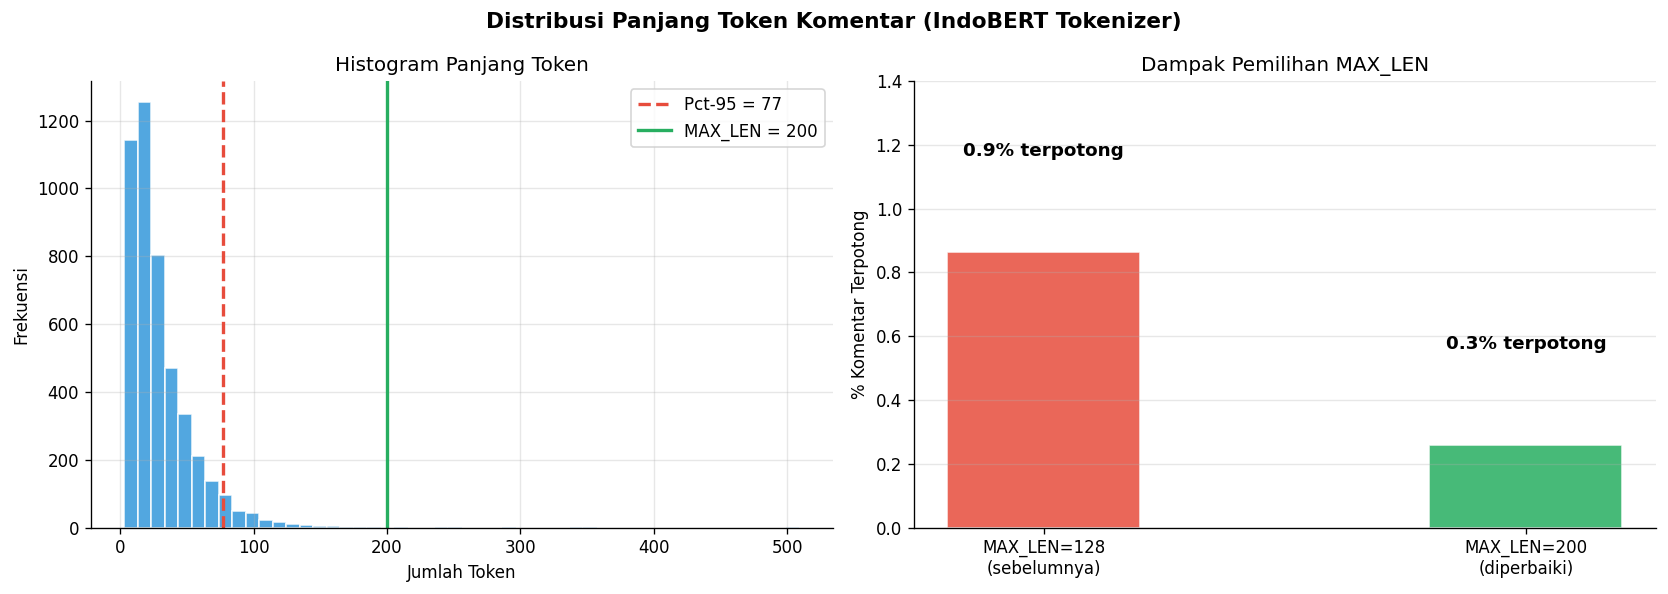


 Analisis token length selesai.
  MAX_LEN=128: 0.9% komentar terpotong
  MAX_LEN=200: 0.3% komentar terpotong â†’ jauh lebih baik


In [ ]:
# Analisis distribusi token length â€” justifikasi empiris MAX_LEN
print(' Mengukur distribusi panjang token komentar...')
# Gunakan tokenizer yang sudah dimuat (jalankan setelah cell model load)
token_lengths = df_model['teks_indobert'].apply(
  lambda x: len(tokenizer_bert.encode(str(x), add_special_tokens=True))
)

q = token_lengths.quantile([0.50, 0.75, 0.90, 0.95, 0.99])
print('\nDistribusi panjang token (termasuk [CLS] & [SEP]):')
print(f'  Median (50%)  : {int(q[0.50])} token')
print(f'  Pct 75%  : {int(q[0.75])} token')
print(f'  Pct 90%  : {int(q[0.90])} token')
print(f'  Pct 95%  : {int(q[0.95])} token  â† referensi MAX_LEN')
print(f'  Pct 99%  : {int(q[0.99])} token')
print(f'  Maximum  : {int(token_lengths.max())} token')

# Visualisasi distribusi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Distribusi Panjang Token Komentar (IndoBERT Tokenizer)', fontsize=13, fontweight='bold')

axes[0].hist(token_lengths, bins=50, color='#3498db', edgecolor='white', alpha=0.85)
axes[0].axvline(int(q[0.95]), color='#e74c3c', lw=2, ls='--', label=f'Pct-95 = {int(q[0.95])}')
axes[0].axvline(200, color='#27ae60', lw=2, ls='-',  label='MAX_LEN = 200')
axes[0].set_xlabel('Jumlah Token'); axes[0].set_ylabel('Frekuensi')
axes[0].set_title('Histogram Panjang Token'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].spines[['top','right']].set_visible(False)

pct_truncated_128 = (token_lengths > 128).sum() / len(token_lengths) * 100
pct_truncated_200 = (token_lengths > 200).sum() / len(token_lengths) * 100
axes[1].bar(['MAX_LEN=128\n(sebelumnya)', 'MAX_LEN=200\n(diperbaiki)'],
  [pct_truncated_128, pct_truncated_200],
  color=['#e74c3c', '#27ae60'], edgecolor='white', alpha=0.85, width=0.4)
for i, v in enumerate([pct_truncated_128, pct_truncated_200]):
  axes[1].text(i, v + 0.3, f'{v:.1f}% terpotong', ha='center', fontsize=11, fontweight='bold')
axes[1].set_ylabel('% Komentar Terpotong'); axes[1].set_ylim(0, max(pct_truncated_128, 1) * 1.4)
axes[1].set_title('Dampak Pemilihan MAX_LEN'); axes[1].grid(axis='y', alpha=0.3)
axes[1].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()
print(f'\n Analisis token length selesai.')
print(f'  MAX_LEN=128: {pct_truncated_128:.1f}% komentar terpotong')
print(f'  MAX_LEN=200: {pct_truncated_200:.1f}% komentar terpotong â†’ jauh lebih baik')

### 6B.1 WeightedTrainer & Hyperparameter


In [ ]:
bert_log_history = {}  # simpan log per split untuk learning curve
import shutil, os
from sklearn.utils.class_weight import compute_class_weight

# -- Custom Trainer dengan class weights --
class WeightedTrainer(Trainer):
  def __init__(self, cw, *args, **kwargs):
    super().__init__(*args, **kwargs)
    self.cw = torch.tensor(cw, dtype=torch.float).to(self.args.device)

  def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=0):
    labels  = inputs.pop('labels')
    outputs = model(**inputs)
    # PERBAIKAN: tambah label_smoothing 0.1 untuk regularisasi IndoBERT
    loss  = nn.CrossEntropyLoss(weight=self.cw, label_smoothing=0.1)(
    outputs.logits.view(-1, 3), labels.view(-1))
    return (loss, outputs) if return_outputs else loss

# Hyperparameter IndoBERT
MAX_LEN  = 200
BATCH_TRAIN = 16
BATCH_EVAL  = 32
EPOCHS  = 10
LR  = 3e-5
WARMUP_RATIO  = 0.15
WEIGHT_DECAY  = 0.02
PATIENCE  = 4
GRAD_ACCUM_STEPS = 2

print(f' Fine-tuning IndoBERT â€” 3 skenario split...')
print(f'  Device: {device.upper()} | Batch: {BATCH_TRAIN} | Epochs: {EPOCHS} | LR: {LR}')
print(f'  MAX_LEN={MAX_LEN}, WARMUP={WARMUP_RATIO}, WD={WEIGHT_DECAY}, PATIENCE={PATIENCE}, GRAD_ACCUM={GRAD_ACCUM_STEPS}')


 Fine-tuning IndoBERT â€” 3 skenario split...
  Device: CUDA | Batch: 16 | Epochs: 10 | LR: 3e-05
  MAX_LEN=200, WARMUP=0.15, WD=0.02, PATIENCE=4, GRAD_ACCUM=2


### 6B.2 Training IndoBERT â€” 3 Skenario Split


In [ ]:
for split_label in splits_order:
  print(f'\n{"="*55}')
  print(f'  Split {split_label}')
  print(f'{"="*55}')

  torch.manual_seed(42); np.random.seed(42); random.seed(42)
  if torch.cuda.is_available(): torch.cuda.manual_seed_all(42)

  d = bert_split_data[split_label]
  Xtr, Xval, Xte = d['X_train'], d['X_val'], d['X_test']
  ytr, yval, yte = d['y_train'], d['y_val'], d['y_test']

  # PERBAIKAN: hitung class weight dari data ASLI sebelum oversampling
  ytr_original = d['y_train_original']
  cw = compute_class_weight('balanced', classes=np.unique(ytr_original), y=ytr_original)
  print(f'  Class weights: { {i: round(float(w),4) for i,w in enumerate(cw)} }')

  train_ds = KomentarDataset(Xtr,  ytr,  tokenizer_bert, MAX_LEN)
  val_ds  = KomentarDataset(Xval, yval, tokenizer_bert, MAX_LEN)
  test_ds  = KomentarDataset(Xte,  yte,  tokenizer_bert, MAX_LEN)
  print(f'  Train={len(train_ds):,} | Val={len(val_ds):,} | Test={len(test_ds):,}')

  model_s = AutoModelForSequenceClassification.from_pretrained(
  MODEL_NAME, num_labels=3, ignore_mismatched_sizes=True)
  model_s = model_s.to(device)

  out_dir = f'outputs/models/bert_{split_label.replace("/", "_")}'
  steps_per_ep = len(train_ds) // BATCH_TRAIN

  args = TrainingArguments(
  output_dir=out_dir,
  num_train_epochs=EPOCHS,
  per_device_train_batch_size=BATCH_TRAIN,
  per_device_eval_batch_size=BATCH_EVAL,
  learning_rate=LR,
  warmup_ratio=WARMUP_RATIO,
  weight_decay=WEIGHT_DECAY,
  gradient_accumulation_steps=GRAD_ACCUM_STEPS,
  eval_strategy='epoch',
  save_strategy='epoch',
  load_best_model_at_end=True,
  metric_for_best_model='f1',
  greater_is_better=True,
  save_total_limit=2,
  max_grad_norm=1.0,
  logging_dir=f'{out_dir}/logs',
  logging_steps=50,
  report_to='none',
  fp16=(device == 'cuda'),
  )

  trainer = WeightedTrainer(
  cw=cw, model=model_s, args=args,
  train_dataset=train_ds, eval_dataset=val_ds,
  compute_metrics=compute_metrics,
  callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],  # patience=4
  )

  t0 = time.time()
  trainer.train()
  waktu = time.time() - t0

  # Eval pada test set
  preds_out = trainer.predict(test_ds)
  y_pred_b  = np.argmax(preds_out.predictions, axis=1)
  y_prob_b  = torch.softmax(torch.tensor(preds_out.predictions), dim=1).numpy()

  acc_b  = accuracy_score(yte, y_pred_b)
  f1_b  = f1_score(yte, y_pred_b, average='macro', zero_division=0)
  prec_b = precision_score(yte, y_pred_b, average='macro', zero_division=0)
  rec_b  = recall_score(yte, y_pred_b, average='macro', zero_division=0)
  auc_b  = roc_auc_score(yte, y_prob_b, multi_class='ovr', average='macro')
  cm_b  = confusion_matrix(yte, y_pred_b)
  cr_b  = classification_report(yte, y_pred_b,
  target_names=['Negatif','Netral','Positif'],
  zero_division=0)

  hasil_semua.append({
  'Model': 'IndoBERT', 'Split': split_label,
  'Akurasi Train': None,
  'Akurasi': round(acc_b, 4), 'Precision': round(prec_b, 4),
  'Recall': round(rec_b, 4), 'F1-Score': round(f1_b, 4),
  'ROC-AUC': round(auc_b, 4),
  'Waktu Train (s)': round(waktu, 1),
  'Waktu Pred (s)': round(preds_out.metrics.get('test_runtime', 0), 4),
  })
  cm_store[f'IndoBERT_{split_label}'] = (cm_b, cr_b, y_pred_b, y_prob_b)

  best_ep = trainer.state.best_epoch if hasattr(trainer.state, 'best_epoch') else '?'
  loss_val = trainer.state.log_history[-1].get('eval_loss', '?')
  print(f'  Selesai {waktu:.1f}s | Best Epoch={best_ep} | Eval Loss={loss_val}')
  print(f'  Acc={acc_b:.4f} | F1={f1_b:.4f} | AUC={auc_b:.4f}')

  bert_log_history[split_label] = trainer.state.log_history  # simpan log split ini
  if os.path.exists(out_dir):
    shutil.rmtree(out_dir)

print('\n Fine-tuning IndoBERT 3 skenario selesai.')



  Split 80/20
  Class weights: {0: 0.4893, 1: 1.811, 2: 2.4755}


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


  Train=6,618 | Val=463 | Test=926


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
[transformers] `logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  Selesai 707.2s | Best Epoch=? | Eval Loss=?
  Acc=0.7739 | F1=0.6852 | AUC=0.8186

 Fine-tuning IndoBERT 3 skenario selesai.


In [ ]:
print('=' * 60)
print('  REKAP EVALUASI INDOBERT â€” 3 SKENARIO SPLIT')
print('=' * 60)
for split in splits_order:
  baris = next((r for r in hasil_semua
  if r['Model']=='IndoBERT' and r['Split']==split), None)
  if baris:
    print(f'  Split {split}: Acc={baris["Akurasi"]:.4f} | '
    f'F1={baris["F1-Score"]:.4f} | AUC={baris["ROC-AUC"]:.4f}')

  REKAP EVALUASI INDOBERT â€” 3 SKENARIO SPLIT
  Split 80/20: Acc=0.7592 | F1=0.6837 | AUC=0.8185
  Split 75/25: Acc=0.7796 | F1=0.6808 | AUC=0.8295
  Split 70/30: Acc=0.7739 | F1=0.6852 | AUC=0.8186


---
## 8. Evaluasi & Visualisasi

Metrik: Accuracy, Precision, Recall, F1-macro, ROC-AUC.
Visualisasi: WordCloud, Confusion Matrix, ROC, Learning Curve, Feature Importance, dll.


In [ ]:
df_hasil = pd.DataFrame(hasil_semua)

df_hasil['_mo'] = df_hasil['Model'].map({'SVM': 0, 'IndoBERT': 1})
df_hasil['_so'] = df_hasil['Split'].map({s: i for i,s in enumerate(splits_order)})
df_hasil = df_hasil.sort_values(['_mo','_so']).drop(columns=['_mo','_so']).reset_index(drop=True)

print('=' * 90)
print('  REKAP EVALUASI â€” SVM vs IndoBERT (3 Skenario Split)')
print('=' * 90)
print(df_hasil.to_string(index=False))

df_hasil.to_csv('outputs/reports/rekap_evaluasi.csv', index=False)
print('\n Tersimpan: rekap_evaluasi.csv')


  REKAP EVALUASI â€” SVM vs IndoBERT (3 Skenario Split)
   Model Split  Akurasi Train  Akurasi  Precision  Recall  F1-Score  ROC-AUC  Waktu Train (s)  Waktu Pred (s)
     SVM 80/20         0.9468   0.7387     0.6381  0.6342    0.6350   0.8513            0.445          0.0040
     SVM 75/25         0.9470   0.7364     0.6411  0.6448    0.6420   0.8528            0.469          0.0178
     SVM 70/30         0.9676   0.7408     0.6497  0.6306    0.6389   0.8522            0.531          0.0130
IndoBERT 80/20            NaN   0.7592     0.6828  0.6856    0.6837   0.8185          807.100          2.3887
IndoBERT 75/25            NaN   0.7796     0.7162  0.6580    0.6808   0.8295          918.500          3.0120
IndoBERT 70/30            NaN   0.7739     0.6885  0.6877    0.6852   0.8186          707.200          3.5552

 Tersimpan: rekap_evaluasi.csv


### 8.1 WordCloud per Sentimen


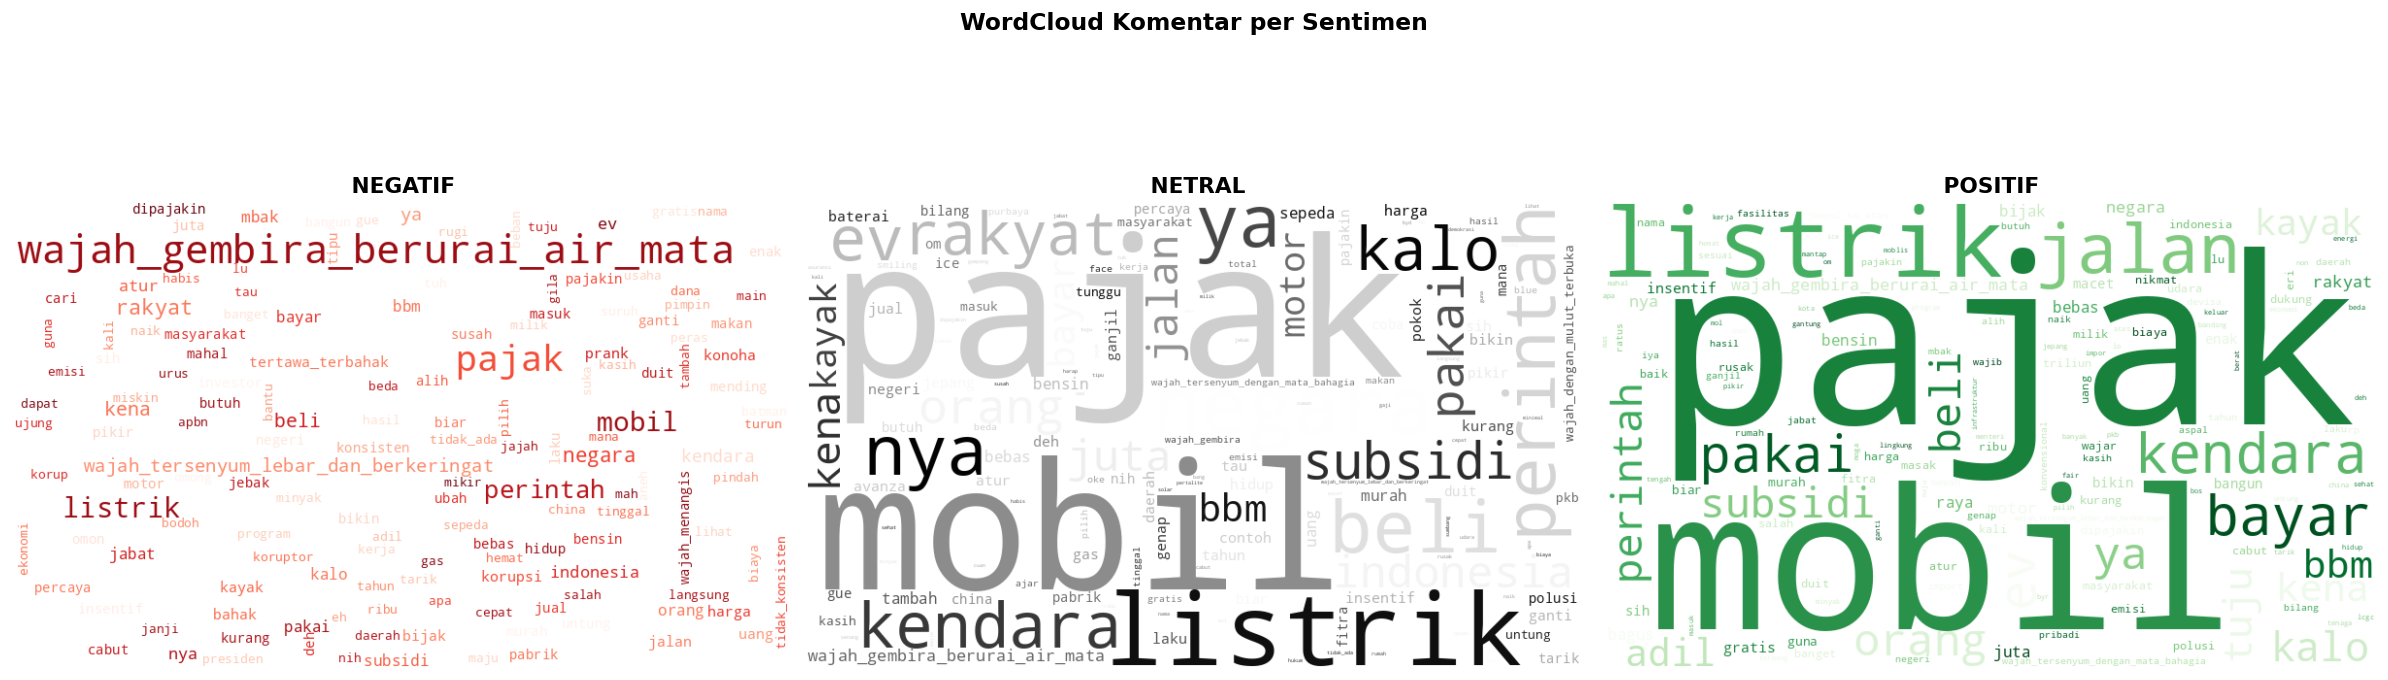

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
fig.suptitle('WordCloud Komentar per Sentimen', fontsize=14, fontweight='bold')

cfgs = [(0,' NEGATIF','Reds'), (1,' NETRAL','Greys'), (2,' POSITIF','Greens')]
for ax, (lv, judul, cmap) in zip(axes, cfgs):
  teks = ' '.join(df_model[df_model['label']==lv]['teks_svm'].dropna())
  if teks.strip():
    wc = WordCloud(width=800, height=480, background_color='white',
    colormap=cmap, max_words=150, collocations=False).generate(teks)
    ax.imshow(wc, interpolation='bilinear')
  else:
    ax.text(0.5, 0.5, 'Tidak ada data', ha='center', va='center')
  ax.set_title(judul, fontsize=13, fontweight='bold'); ax.axis('off')

plt.tight_layout()
plt.show()

### 8.5 Confusion Matrix SVM â€” Semua Split


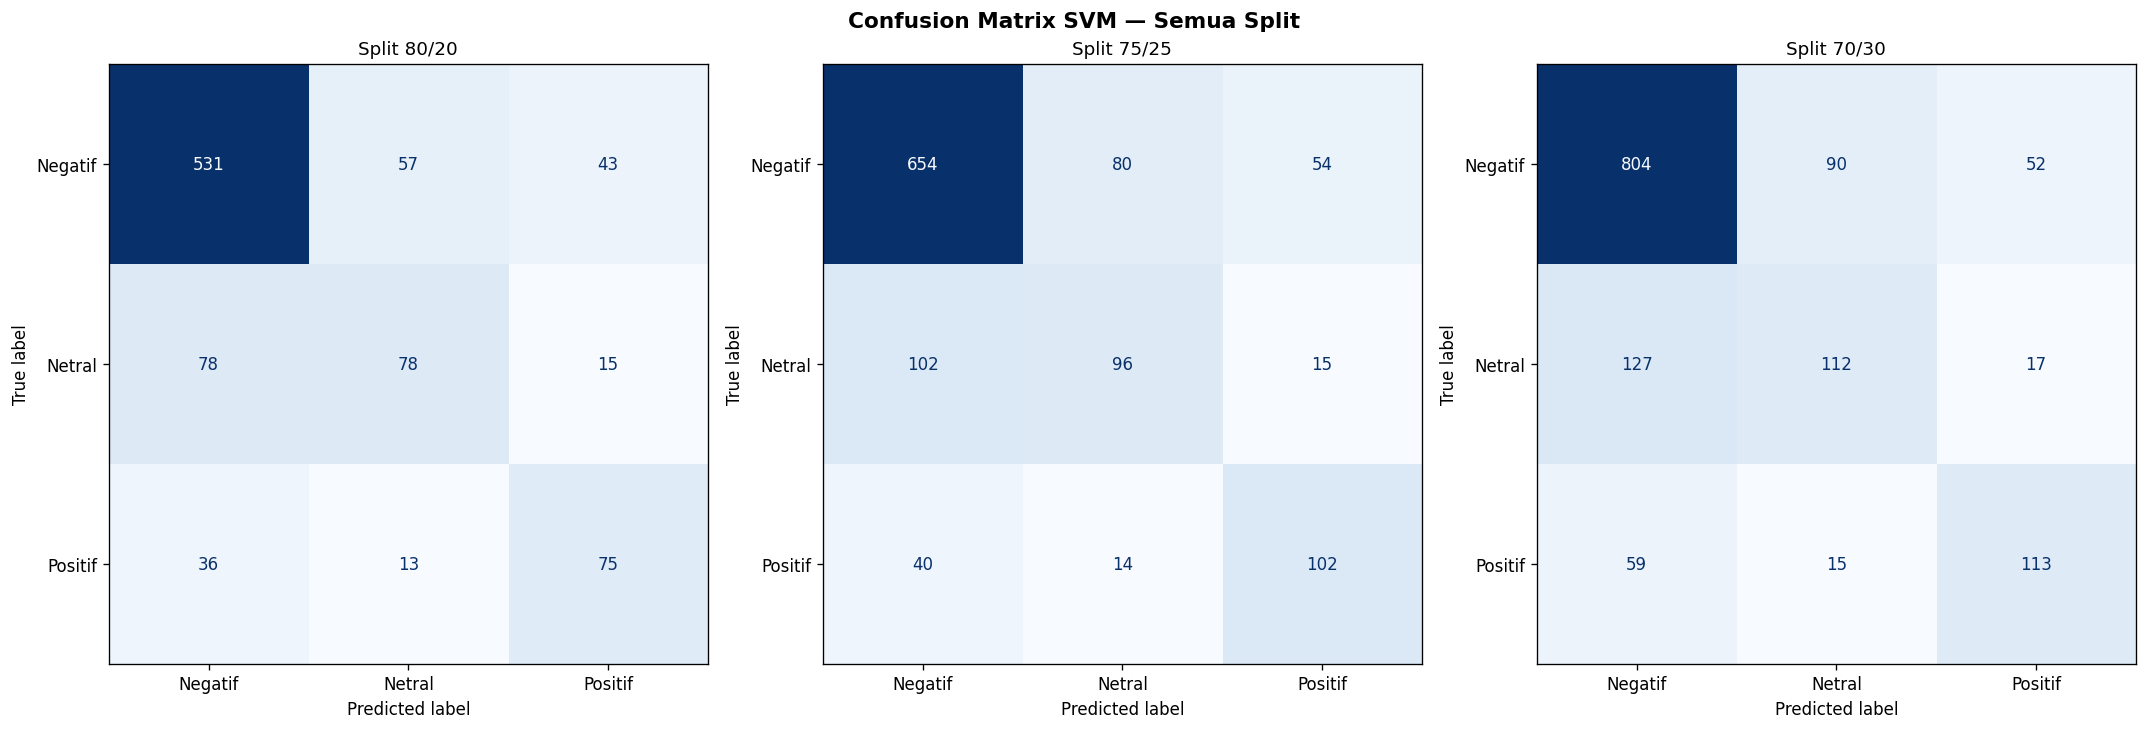

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Confusion Matrix SVM â€” Semua Split', fontsize=13, fontweight='bold')

for ax, split in zip(axes, splits_order):
  kunci = f'SVM_{split}'
  if kunci in cm_store:
    ConfusionMatrixDisplay(cm_store[kunci][0], display_labels=label_names).plot(
    ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Split {split}', fontsize=11)

plt.tight_layout()
plt.show()

### 8.5b Confusion Matrix IndoBERT â€” Semua Split


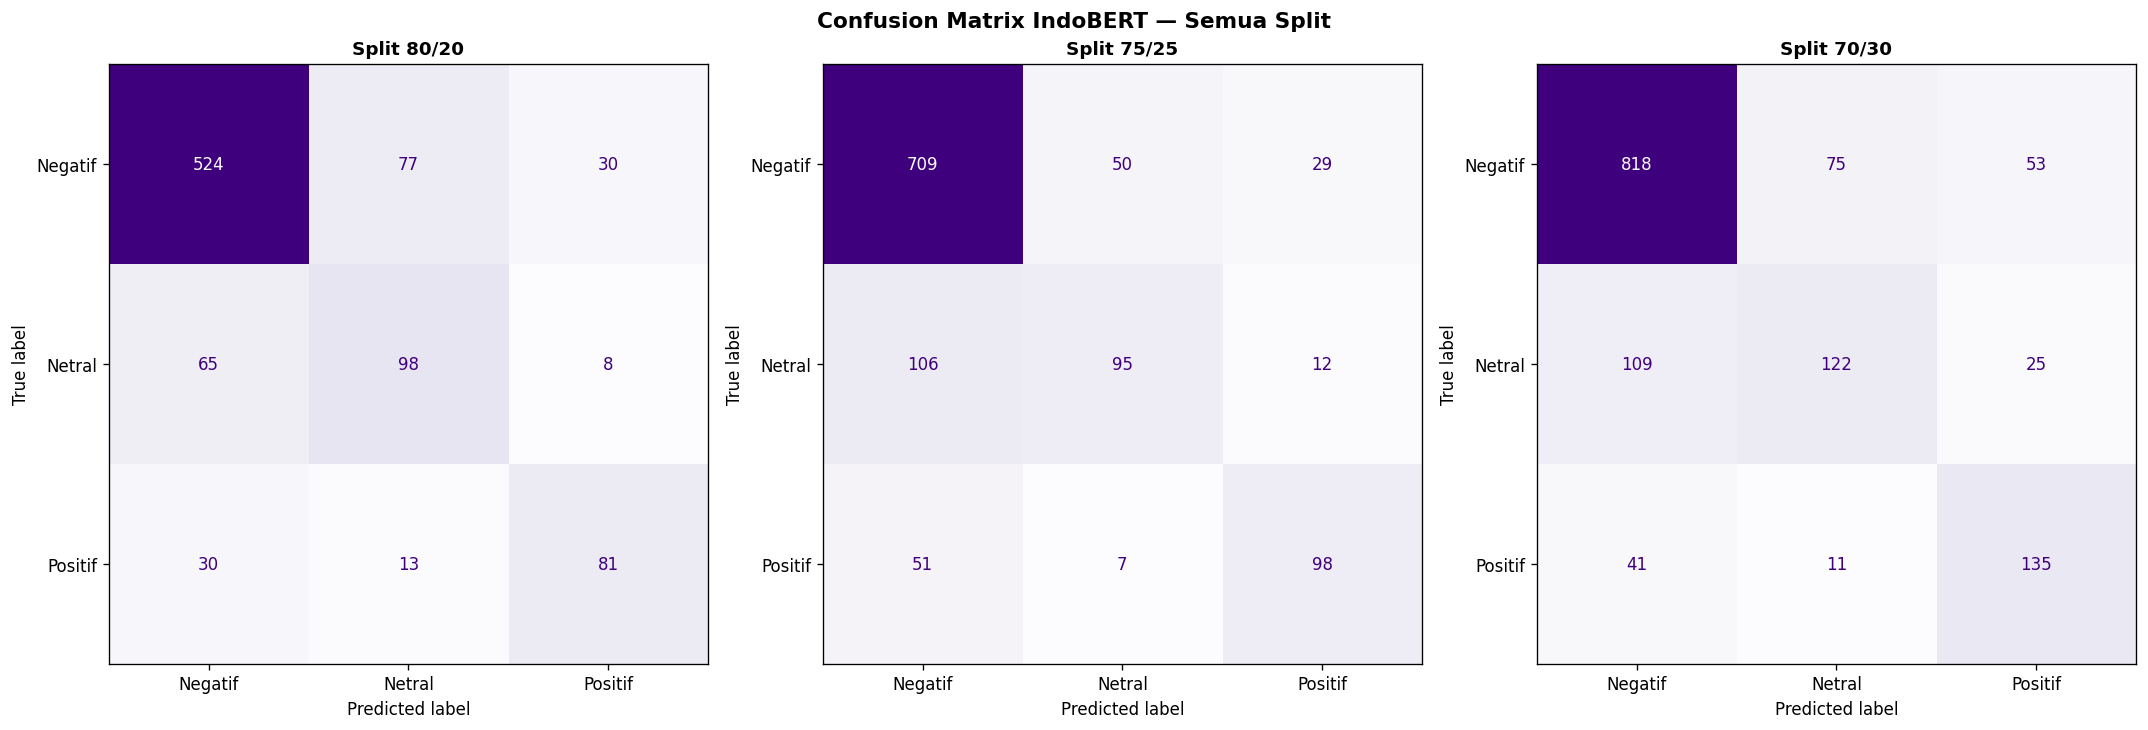

In [ ]:
tersedia = [s for s in splits_order if f'IndoBERT_{s}' in cm_store]
n_cols = max(len(tersedia), 1)
fig, axes = plt.subplots(1, n_cols, figsize=(6*n_cols, 6))
if n_cols == 1: axes = [axes]
fig.suptitle('Confusion Matrix IndoBERT â€” Semua Split', fontsize=13, fontweight='bold')

for ax, split in zip(axes, tersedia):
  ConfusionMatrixDisplay(cm_store[f'IndoBERT_{split}'][0], display_labels=label_names).plot(
  ax=ax, cmap='Purples', colorbar=False)
  ax.set_title(f'Split {split}', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### 8.6 ROC Curve â€” SVM vs IndoBERT


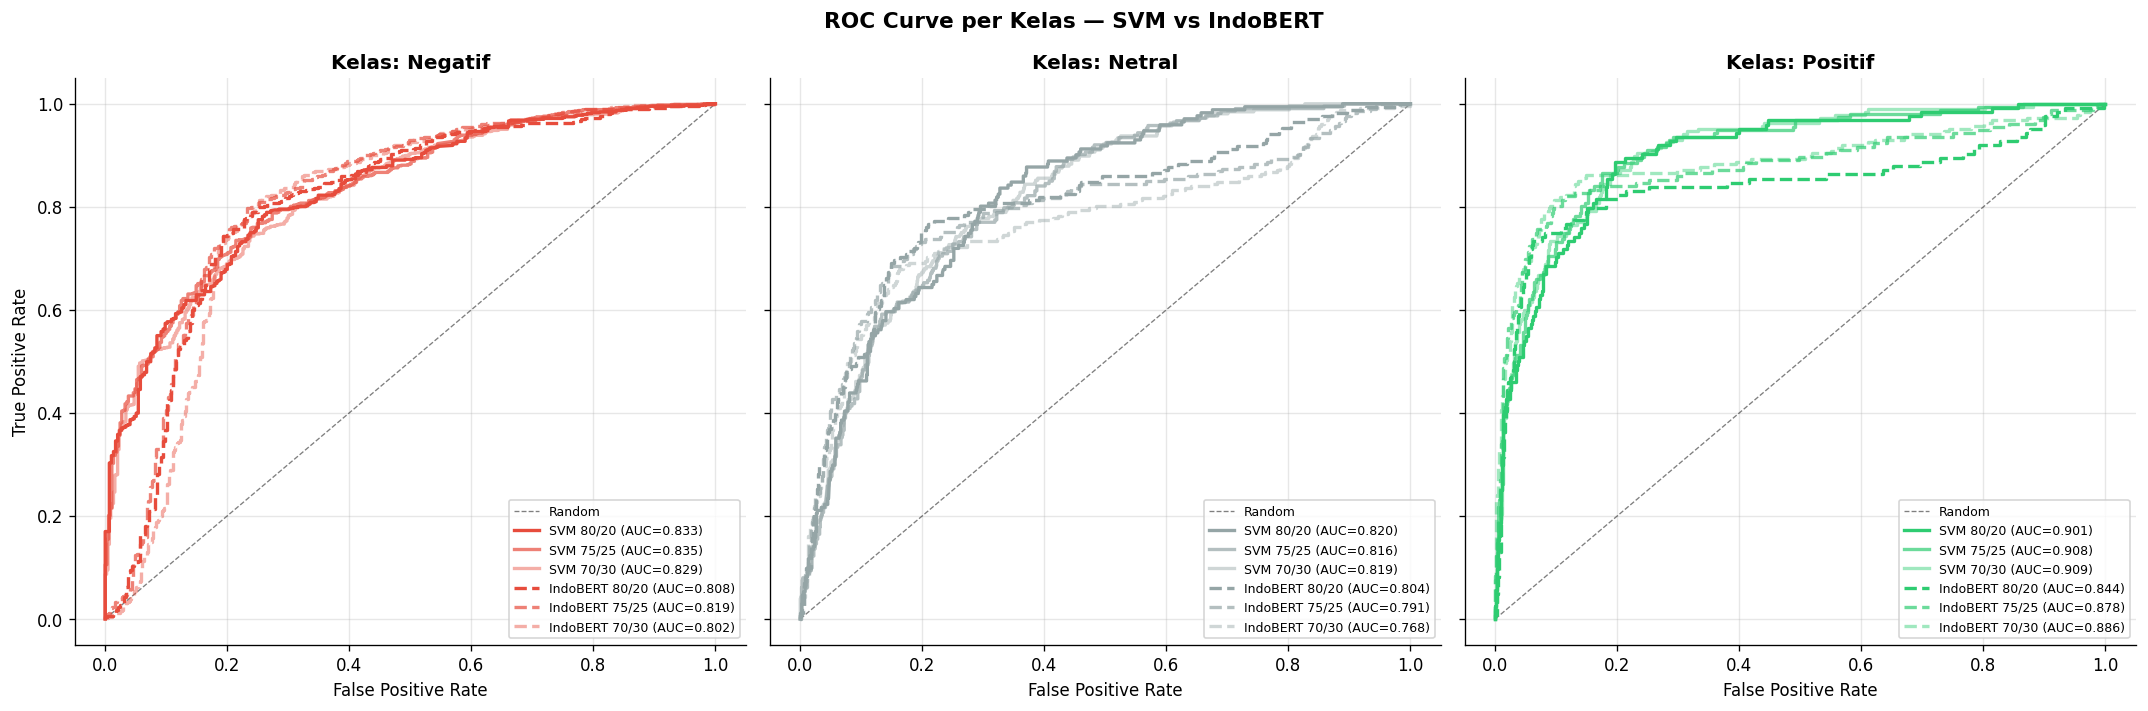

 ROC Curve tersimpan.


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import label_binarize

nama_kelas  = {0:'Negatif', 1:'Netral', 2:'Positif'}
classes  = [0, 1, 2]
warna_kelas  = {0:'#e74c3c', 1:'#95a5a6', 2:'#2ecc71'}
alpha_per_split = {'80/20': 1.0, '75/25': 0.7, '70/30': 0.45}

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
fig.suptitle('ROC Curve per Kelas â€” SVM vs IndoBERT', fontsize=13, fontweight='bold')

for ax, cls_idx in zip(axes, classes):
  ax.plot([0,1], [0,1], 'k--', lw=0.8, alpha=0.5, label='Random')

  # SVM
  for split in splits_order:
    kunci = f'SVM_{split}'
    if kunci not in cm_store: continue
    _, _, _, yprob = cm_store[kunci]
    yte_s = split_data[split]['y_test']
    y_bin = label_binarize(yte_s, classes=classes)
    fpr, tpr, _ = roc_curve(y_bin[:, cls_idx], yprob[:, cls_idx])
    auc_val = roc_auc_score(y_bin[:, cls_idx], yprob[:, cls_idx])
    ax.plot(fpr, tpr, color=warna_kelas[cls_idx], lw=2, ls='-',
    alpha=alpha_per_split[split], label=f'SVM {split} (AUC={auc_val:.3f})')

  # IndoBERT
  for split in splits_order:
    kunci = f'IndoBERT_{split}'
    if kunci not in cm_store: continue
    _, _, _, yprob_b = cm_store[kunci]
    yte_b = bert_split_data[split]['y_test']
    y_bin = label_binarize(yte_b, classes=classes)
    fpr, tpr, _ = roc_curve(y_bin[:, cls_idx], yprob_b[:, cls_idx])
    auc_val = roc_auc_score(y_bin[:, cls_idx], yprob_b[:, cls_idx])
    ax.plot(fpr, tpr, color=warna_kelas[cls_idx], lw=2, ls='--',
    alpha=alpha_per_split[split], label=f'IndoBERT {split} (AUC={auc_val:.3f})')

  ax.set_title(f'Kelas: {nama_kelas[cls_idx]}', fontsize=12, fontweight='bold')
  ax.set_xlabel('False Positive Rate')
  if cls_idx == 0: ax.set_ylabel('True Positive Rate')
  ax.legend(fontsize=7.5, loc='lower right')
  ax.grid(alpha=0.3); ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()
print(' ROC Curve tersimpan.')

### 8.8 Learning Curve â€” SVM


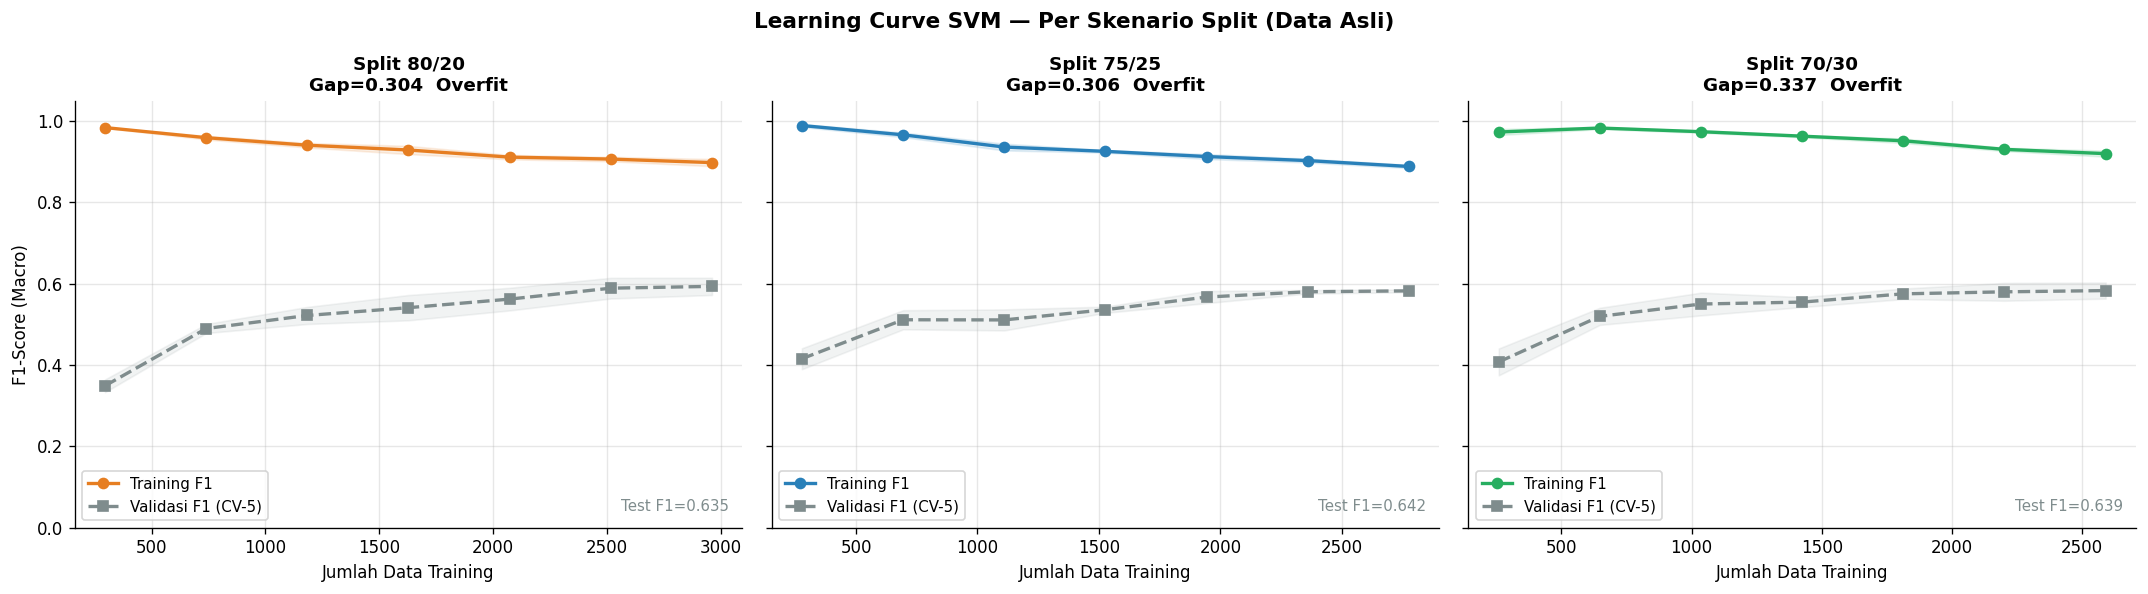

In [ ]:
from sklearn.model_selection import learning_curve

warna_split = {'80/20': '#e67e22', '75/25': '#2980b9', '70/30': '#27ae60'}
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
fig.suptitle('Learning Curve SVM â€” Per Skenario Split (Data Asli)', fontsize=13, fontweight='bold')

for ax, split_label in zip(axes, splits_order):
  c_lc = best_C_per_split.get(split_label, best_C)
  model_lc = CalibratedClassifierCV(
  LinearSVC(C=c_lc, class_weight='balanced', max_iter=2000, random_state=42), cv=3)

  sizes, s_train, s_val = learning_curve(
  model_lc,
  split_data[split_label]['X_train_orig'],
  split_data[split_label]['y_train_orig'],
  train_sizes=np.linspace(0.1, 1.0, 7), cv=5, scoring='f1_macro', n_jobs=-1)

  tm, ts = s_train.mean(1), s_train.std(1)
  vm, vs = s_val.mean(1),  s_val.std(1)
  warna  = warna_split[split_label]

  ax.plot(sizes, tm, 'o-', color=warna,  lw=2, label='Training F1')
  ax.fill_between(sizes, tm-ts, tm+ts, alpha=0.12, color=warna)
  ax.plot(sizes, vm, 's--', color='#7f8c8d', lw=2, label='Validasi F1 (CV-5)')
  ax.fill_between(sizes, vm-vs, vm+vs, alpha=0.10, color='#7f8c8d')

  gap = tm[-1] - vm[-1]
  status = ' Overfit' if gap > 0.15 else ' OK'
  ax.set_title(f'Split {split_label}\nGap={gap:.3f} {status}', fontsize=11, fontweight='bold')
  ax.set_xlabel('Jumlah Data Training')
  if split_label == '80/20': ax.set_ylabel('F1-Score (Macro)')
  ax.set_ylim(0, 1.05); ax.grid(alpha=0.3); ax.legend(fontsize=9)
  ax.spines[['top','right']].set_visible(False)

  test_f1_row = df_hasil[(df_hasil['Model'] == 'SVM') & (df_hasil['Split'] == split_label)]
  if not test_f1_row.empty:
    test_f1_value = test_f1_row['F1-Score'].values[0]
    f1_text = f'{test_f1_value:.3f}'
  else:
    f1_text = 'â€”'

  ax.annotate(f'Test F1={f1_text}',
  xy=(0.98,0.04), xycoords='axes fraction', ha='right', fontsize=9, color='#7f8c8d')

plt.tight_layout()
plt.show()

### 8.8b Learning Curve â€” IndoBERT


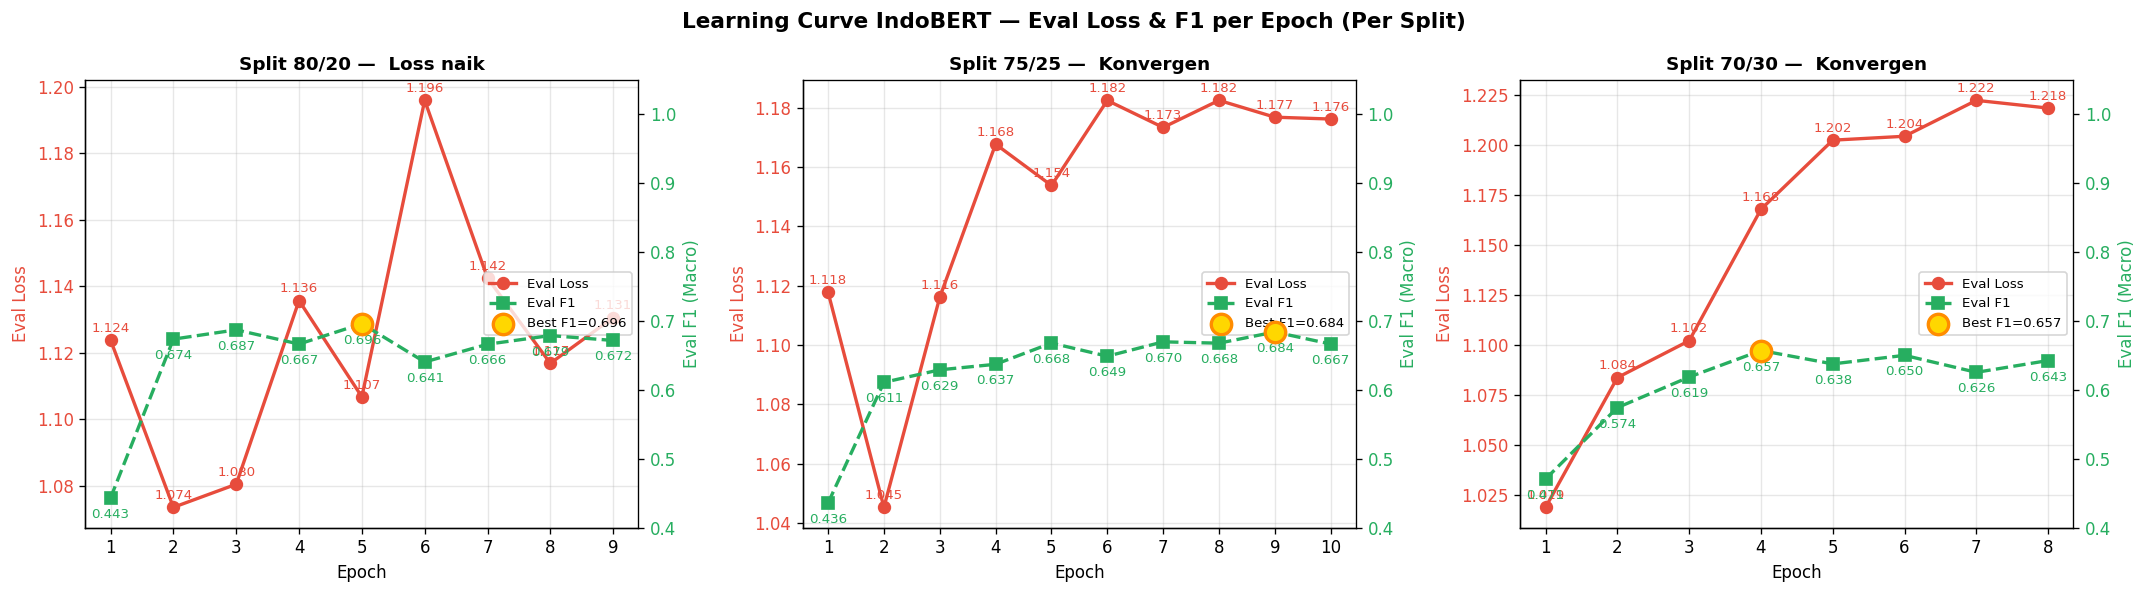

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Learning Curve IndoBERT â€” Eval Loss & F1 per Epoch (Per Split)',
  fontsize=13, fontweight='bold')
warna_loss = '#e74c3c'
warna_f1  = '#27ae60'

for ax, split_label in zip(axes, splits_order):
  kunci_log = f'bert_log_{split_label.replace("/", "_")}'
  log = bert_log_history.get(split_label, [])
  if not log:
    ax.text(0.5, 0.5, f'Log {split_label}\ntidak tersedia',
    ha='center', va='center', transform=ax.transAxes, fontsize=11)
    ax.set_title(f'Split {split_label}', fontsize=11, fontweight='bold')
    continue

  eval_logs = [(h.get('epoch',0), h.get('eval_loss'), h.get('eval_f1'))
  for h in log if 'eval_loss' in h]
  if not eval_logs:
    ax.text(0.5, 0.5, 'Tidak ada eval log', ha='center', va='center',
    transform=ax.transAxes); continue

  ep  = [e[0] for e in eval_logs]
  el  = [e[1] for e in eval_logs]
  ef  = [e[2] for e in eval_logs]

  ax.plot(ep, el, 'o-', color=warna_loss, lw=2, markersize=7, label='Eval Loss')
  for e, l in zip(ep, el):
    if l:
      ax.annotate(f'{l:.3f}', xy=(e, l), xytext=(0, 5),
      textcoords='offset points', fontsize=8, ha='center', color=warna_loss)
  ax.set_ylabel('Eval Loss', color=warna_loss); ax.tick_params(axis='y', labelcolor=warna_loss)

  ax2 = ax.twinx()
  ax2.plot(ep, ef, 's--', color=warna_f1, lw=2, markersize=7, label='Eval F1')
  for e, f in zip(ep, ef):
    if f:
      ax2.annotate(f'{f:.3f}', xy=(e, f), xytext=(0, -12),
      textcoords='offset points', fontsize=8, ha='center', color=warna_f1)
  ax2.set_ylabel('Eval F1 (Macro)', color=warna_f1)
  ax2.tick_params(axis='y', labelcolor=warna_f1); ax2.set_ylim(0.4, 1.05)

  best_i = int(np.argmax([f if f else 0 for f in ef]))
  ax2.scatter([ep[best_i]], [ef[best_i]], s=150, color='gold',
  zorder=5, edgecolors='darkorange', linewidths=2, label=f'Best F1={ef[best_i]:.3f}')

  el_clean = [e for e in el if e is not None]
  status = ' Loss naik' if len(el_clean)>=2 and el_clean[-1]>el_clean[-2] else ' Konvergen'
  ax.set_title(f'Split {split_label} â€” {status}', fontsize=11, fontweight='bold')
  ax.set_xlabel('Epoch'); ax.set_xticks([int(e) for e in ep])
  ax.grid(alpha=0.3); ax.legend(fontsize=8, loc='lower right')
  ax.spines[['top','right']].set_visible(False)

  lines1, labels1 = ax.get_legend_handles_labels()
  lines2, labels2 = ax2.get_legend_handles_labels()
  ax.legend(lines1+lines2, labels1+labels2, fontsize=8, loc='center right')

plt.tight_layout()
plt.show()

### 8.14 Classification Report Detail


In [ ]:
print('=' * 65)
print('  CLASSIFICATION REPORT â€” SVM & IndoBERT (Semua Split)')
print('=' * 65)

for split in splits_order:
  kunci = f'SVM_{split}'
  if kunci in cm_store:
    print(f'\n{"â”€"*55}')
    print(f'  SVM (Split {split})')
    print('â”€'*55)
    print(cm_store[kunci][1])

for split in splits_order:
  kunci = f'IndoBERT_{split}'
  if kunci in cm_store:
    print(f'\n{"â”€"*55}')
    print(f'  IndoBERT (Split {split})')
    print('â”€'*55)
    print(cm_store[kunci][1])

print('\n Classification Report selesai.')

  CLASSIFICATION REPORT â€” SVM & IndoBERT (Semua Split)

â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
  SVM (Split 80/20)
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
              precision    recall  f1-score   support

     Negatif       0.82      0.84      0.83       631
      Netral       0.53      0.46      0.49       171
     Positif       0.56      0.60      0.58       124

    accuracy                           0.74       926
   macro avg       0.64      0.63      0.63       926
weighted avg       0.73      0.74      0.74       926


â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
  SVM (Split 75/25)
â”€â”€â”€â”€â”€â”€â”€â

### 8.15 Error Analysis


In [ ]:
rows_err = []

# Error SVM
if 'SVM_80/20' in cm_store:
  _, _, y_pred_svm, _ = cm_store['SVM_80/20']
  for teks, ytrue, ypred in zip(split_data['80/20']['X_test_raw'],
                                split_data['80/20']['y_test'], y_pred_svm):
    if ytrue != ypred:
      rows_err.append({'Komentar': teks[:80], 'Label Asli': nama_label[ytrue],
                       'Prediksi SVM': nama_label[ypred], 'Prediksi BERT': '-', 'Salah oleh': 'SVM'})

# Error IndoBERT
if 'IndoBERT_80/20' in cm_store:
  _, _, y_pred_b, _ = cm_store['IndoBERT_80/20']
  for teks, ytrue, ypred in zip(bert_split_data['80/20']['X_test'],
                                bert_split_data['80/20']['y_test'], y_pred_b):
    if ytrue != ypred:
      rows_err.append({'Komentar': teks[:80], 'Label Asli': nama_label[ytrue],
                       'Prediksi SVM': '-', 'Prediksi BERT': nama_label[ypred], 'Salah oleh': 'IndoBERT'})

df_error = pd.DataFrame(rows_err)
print(f'Total kesalahan SVM  : {(df_error["Salah oleh"]=="SVM").sum():,}')
print(f'Total kesalahan IndoBERT: {(df_error["Salah oleh"]=="IndoBERT").sum():,}')

for model_err, pred_col in [('SVM','Prediksi SVM'), ('IndoBERT','Prediksi BERT')]:
  subset = df_error[df_error['Salah oleh']==model_err].head(5)
  if len(subset):
    print(f'\n--- {model_err}: 5 contoh prediksi salah ---')
    print(subset[['Komentar','Label Asli', pred_col]].to_string(index=False))

print('\nPola kesalahan umum:')
print('  - Komentar sarkastis: "mantap pajaknya makin nyusahin" â†’ False Positive')
print('  - Komentar ambigu  : campuran ekspresi positif-negatif')
print('  - Komentar pendek  : konteks terlalu minim')

df_error.to_csv('outputs/reports/error_analysis.csv', index=False)
print('\n Error analysis tersimpan: error_analysis.csv')

Total kesalahan SVM  : 242
Total kesalahan IndoBERT: 223

--- SVM: 5 contoh prediksi salah ---
                                                                        Komentar Label Asli Prediksi SVM
                             masyarakat tau harga asli pabrik jaman canggih boos     Netral      Negatif
        hidup buah negara bukan_disebuah raja raja suka hati mungut pajak rakyat     Netral      Negatif
kabar pajak murah sifat insentif pancing investor ev bangun pabrik dimarih jangk     Netral      Negatif
             enak beli mobil bayar pajak gilir rakyat dipajakin plus peres ormas    Negatif      Positif
                               trick produsen tuju perintah jaman kolonial halus    Negatif      Positif

--- IndoBERT: 5 contoh prediksi salah ---
                                                                        Komentar Label Asli Prediksi BERT
               Bukan prank, tp semua org yg make fasilitas umum kudu bayar pajak    Positif       Negatif
      Dikira masyara

### 9.2 Ringkasan Performa Akhir


In [ ]:
print('=' * 70)
print('  PERBANDINGAN PERFORMA AKHIR: SVM vs IndoBERT')
print('  (3 Kelas, class_weight=balanced + RandomOverSampler training only)')
print('=' * 70)

for _, r in df_hasil.iterrows():
  print(f'\n {r["Model"]} â€” Split {r["Split"]}:')
  print(f'  Akurasi  : {r["Akurasi"]:.4f} ({r["Akurasi"]*100:.2f}%)')
  print(f'  Precision: {r["Precision"]:.4f} | Recall: {r["Recall"]:.4f}')
  print(f'  F1-Score : {r["F1-Score"]:.4f} | ROC-AUC: {r["ROC-AUC"]:.4f}')

print('\n' + 'â”€'*70)
best = df_hasil.loc[df_hasil['F1-Score'].idxmax()]
print(f'\n Model Terbaik: {best["Model"]} (Split {best["Split"]})')
print(f'  Akurasi : {best["Akurasi"]*100:.2f}%')
print(f'  F1-Score: {best["F1-Score"]:.4f} | ROC-AUC: {best["ROC-AUC"]:.4f}')

f1_bert = df_hasil[df_hasil['Model']=='IndoBERT']['F1-Score'].max()
f1_svm  = df_hasil[df_hasil['Model']=='SVM']['F1-Score'].max()
auc_bert = df_hasil[df_hasil['Model']=='IndoBERT']['ROC-AUC'].max()
auc_svm  = df_hasil[df_hasil['Model']=='SVM']['ROC-AUC'].max()

print(f'\n IndoBERT vs SVM (split terbaik masing-masing):')
print(f'  Selisih F1-Score : {f1_bert - f1_svm:+.4f}')
print(f'  Selisih ROC-AUC  : {auc_bert - auc_svm:+.4f}')

if f1_bert > f1_svm:
  print(f'\n IndoBERT unggul {(f1_bert-f1_svm)*100:.1f}% poin F1 dibanding SVM.')
  print('  IndoBERT memahami konteks kalimat lebih dalam dibanding TF-IDF.')
else:
  print('\n SVM kompetitif dengan IndoBERT pada dataset ini.')

print('\n Catatan:')
print('  â€¢ F1-Macro  â†’ metrik utama (mengatasi class imbalance)')
print('  â€¢ ROC-AUC  â†’ kemampuan diskriminasi model')
print('  â€¢ McNemar\'s Test â†’ uji signifikansi statistik perbedaan antar model')
print('  â†’ Lihat tabel mcnemar_test.csv untuk detail uji signifikansi')
print('\n Analisis selesai.')


  PERBANDINGAN PERFORMA AKHIR: SVM vs IndoBERT
  (3 Kelas, class_weight=balanced + RandomOverSampler training only)

 SVM â€” Split 80/20:
  Akurasi  : 0.7387 (73.87%)
  Precision: 0.6381 | Recall: 0.6342
  F1-Score : 0.6350 | ROC-AUC: 0.8513

 SVM â€” Split 75/25:
  Akurasi  : 0.7364 (73.64%)
  Precision: 0.6411 | Recall: 0.6448
  F1-Score : 0.6420 | ROC-AUC: 0.8528

 SVM â€” Split 70/30:
  Akurasi  : 0.7408 (74.08%)
  Precision: 0.6497 | Recall: 0.6306
  F1-Score : 0.6389 | ROC-AUC: 0.8522

 IndoBERT â€” Split 80/20:
  Akurasi  : 0.7592 (75.92%)
  Precision: 0.6828 | Recall: 0.6856
  F1-Score : 0.6837 | ROC-AUC: 0.8185

 IndoBERT â€” Split 75/25:
  Akurasi  : 0.7796 (77.96%)
  Precision: 0.7162 | Recall: 0.6580
  F1-Score : 0.6808 | ROC-AUC: 0.8295

 IndoBERT â€” Split 70/30:
  Akurasi  : 0.7739 (77.39%)
  Precision: 0.6885 | Recall: 0.6877
  F1-Score : 0.6852 | ROC-AUC: 0.8186

â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â

### 9.3 Simpan File Hasil


In [ ]:
df_model[['text','teks_svm','teks_indobert','label']].to_csv('outputs/reports/data_labeled.csv', index=False)

print('File CSV tersimpan:')
files = ['outputs/reports/data_preprocessing.csv', 'outputs/reports/data_labeled.csv', 'outputs/reports/rekap_evaluasi.csv',
         'outputs/reports/error_analysis.csv', 'outputs/reports/mcnemar_test.csv']
for f in files:
    print(f'  - {f}')

File CSV tersimpan:
  - data_preprocessing.csv
  - data_labeled.csv
  - rekap_evaluasi.csv
  - error_analysis.csv
  - mcnemar_test.csv
